In [ ]:
from google.colab import drive
import pandas as pd
import glob
import os
from scipy import stats

# Prepare Data Source

In [ ]:
# Mount Google Drive ke Google Colab
drive.mount('/content/drive')

# Tentukan jalur (path) folder di Google Drive
raw_data_path = '/content/drive/MyDrive/cyclistic_bike_project/raw_data'
output_dir = '/content/drive/MyDrive/cyclistic_bike_project/cleaned_data'

# Buat folder output otomatis jika belum ada
os.makedirs(output_dir, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Import & Combine Data

In [ ]:
# Combine Data: Membaca dan menggabungkan seluruh file CSV
all_files = glob.glob(os.path.join(raw_data_path, "*.csv"))
print(f"Ditemukan {len(all_files)} file CSV.")

df_list = [pd.read_csv(file) for file in all_files]
df = pd.concat(df_list, ignore_index=True)
df.head()

Ditemukan 12 file CSV.


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,7569BC890583FCD7,classic_bike,2025-01-21 17:23:54.538,2025-01-21 17:37:52.015,Wacker Dr & Washington St,KA1503000072,McClurg Ct & Ohio St,TA1306000029,41.883143,-87.637242,41.892592,-87.617289,member
1,013609308856B7FC,electric_bike,2025-01-11 15:44:06.795,2025-01-11 15:49:11.139,Halsted St & Wrightwood Ave,TA1309000061,Racine Ave & Belmont Ave,TA1308000019,41.929147,-87.649153,41.939743,-87.658865,member
2,EACACD3CE0607C0D,classic_bike,2025-01-02 15:16:27.730,2025-01-02 15:28:03.230,Southport Ave & Waveland Ave,13235,Broadway & Cornelia Ave,13278,41.948226,-87.664071,41.945529,-87.646439,member
3,EAA2485BA64710D3,classic_bike,2025-01-23 08:49:05.814,2025-01-23 08:52:40.047,Southport Ave & Waveland Ave,13235,Southport Ave & Roscoe St,13071,41.948226,-87.664071,41.943739,-87.664020,member
4,7F8BE2471C7F746B,electric_bike,2025-01-16 08:38:32.338,2025-01-16 08:41:06.767,Southport Ave & Waveland Ave,13235,Southport Ave & Roscoe St,13071,41.948226,-87.664071,41.943739,-87.664020,member


# Data Exploration

In [ ]:
# Melihat Struktur Dataframe
print("Informasi Struktur DataFrame:")
df.info()

Informasi Struktur DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5552994 entries, 0 to 5552993
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             object 
 1   rideable_type       object 
 2   started_at          object 
 3   ended_at            object 
 4   start_station_name  object 
 5   start_station_id    object 
 6   end_station_name    object 
 7   end_station_id      object 
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       object 
dtypes: float64(4), object(9)
memory usage: 550.8+ MB


In [ ]:
# Analisis deskriptif
df.describe()

,start_lat,start_lng,end_lat,end_lng
count,5.552994e+06,5.552994e+06,5.547459e+06,5.547459e+06
mean,4.190366e+01,-8.764648e+01,4.190411e+01,-8.764683e+01
std,4.443323e-02,2.726130e-02,4.460469e-02,2.746640e-02
min,4.164850e+01,-8.789000e+01,4.149000e+01,-8.810000e+01
25%,4.188213e+01,-8.766000e+01,4.188241e+01,-8.766000e+01
50%,4.189859e+01,-8.764177e+01,4.189964e+01,-8.764275e+01
75%,4.193000e+01,-8.762991e+01,4.193000e+01,-8.763000e+01
max,4.207000e+01,-8.752000e+01,4.221000e+01,-8.742000e+01


In [ ]:
# Cek nilai null dan duplikat
print("\nJumlah Nilai Null per Kolom:")
print(df.isnull().sum())

print("\nJumlah baris duplikat:")
print(df.duplicated().sum())


Jumlah Nilai Null per Kolom:
ride_id                     0
rideable_type               0
started_at                  0
ended_at                    0
start_station_name    1184673
start_station_id      1184673
end_station_name      1243305
end_station_id        1243305
start_lat                   0
start_lng                   0
end_lat                  5535
end_lng                  5535
member_casual               0
dtype: int64

Jumlah baris duplikat:
0


# Cleaning Data

In [ ]:
# Data Cleaning & Transformation
df_clean = df.dropna(subset=['start_station_name', 'end_station_name', 'end_lat', 'end_lng']).copy()

In [ ]:
# Konversi kolom waktu ke datetime
df_clean['started_at'] = pd.to_datetime(df_clean['started_at'])
df_clean['ended_at'] = pd.to_datetime(df_clean['ended_at'])

In [ ]:
# Hitung durasi perjalanan (dalam menit) dan nama hari
df_clean['month'] = df_clean['started_at'].dt.month_name()
df_clean['day_of_week'] = df_clean['started_at'].dt.day_name()
df_clean['hour_of_day'] = df_clean['started_at'].dt.hour
df_clean['ride_length_min'] = (df_clean['ended_at'] - df_clean['started_at']).dt.total_seconds() / 60
df_clean['ride_length_min'] = df_clean['ride_length_min'].round(2)

In [ ]:
# Filter data anomali (durasi > 1 menit & < 1440)
df_clean = df_clean[(df_clean['ride_length_min'] > 1)]

In [ ]:
# Melihat Struktur Dataframe setelah dibersihkan
print("Informasi Struktur DataFrame:")
df_clean.info()

# Cek nilai null
print("\nJumlah Nilai Null per Kolom:")
print(df_clean.isnull().sum())

print("\nJumlah Nilai Null per Kolom:")
df_clean.describe()

Informasi Struktur DataFrame:
<class 'pandas.core.frame.DataFrame'>
Index: 3661552 entries, 0 to 5552993
Data columns (total 17 columns):
 #   Column              Dtype         
---  ------              -----         
 0   ride_id             object        
 1   rideable_type       object        
 2   started_at          datetime64[ns]
 3   ended_at            datetime64[ns]
 4   start_station_name  object        
 5   start_station_id    object        
 6   end_station_name    object        
 7   end_station_id      object        
 8   start_lat           float64       
 9   start_lng           float64       
 10  end_lat             float64       
 11  end_lng             float64       
 12  member_casual       object        
 13  month               object        
 14  day_of_week         object        
 15  hour_of_day         int32         
 16  ride_length_min     float64       
dtypes: datetime64[ns](2), float64(5), int32(1), object(9)
memory usage: 488.9+ MB

Jumlah Nilai Null 

,started_at,ended_at,start_lat,start_lng,end_lat,end_lng,hour_of_day,ride_length_min
count,3661552,3661552,3.661552e+06,3.661552e+06,3.661552e+06,3.661552e+06,3.661552e+06,3.661552e+06
mean,2025-07-18 17:35:32.010707200,2025-07-18 17:51:35.410845952,4.190086e+01,-8.764480e+01,4.190144e+01,-8.764512e+01,1.391520e+01,1.605667e+01
min,2024-12-31 18:54:41.803000,2025-01-01 00:00:51.212000,4.164850e+01,-8.784411e+01,4.164850e+01,-8.784396e+01,0.000000e+00,1.010000e+00
25%,2025-05-23 17:41:13.372999936,2025-05-23 17:58:52.744999936,4.188103e+01,-8.765703e+01,4.188132e+01,-8.765842e+01,1.000000e+01,5.830000e+00
50%,2025-07-24 08:46:58.606000128,2025-07-24 09:00:20.264499968,4.189488e+01,-8.764117e+01,4.189576e+01,-8.764117e+01,1.500000e+01,9.970000e+00
75%,2025-09-20 09:42:27.837000192,2025-09-20 10:02:24.802999808,4.192586e+01,-8.762784e+01,4.192657e+01,-8.762858e+01,1.700000e+01,1.766000e+01
max,2025-12-31 23:53:24.274000,2025-12-31 23:57:07.715000,4.206485e+01,-8.752823e+01,4.206485e+01,-8.752823e+01,2.300000e+01,1.499640e+03
std,NaN,NaN,4.306414e-02,2.638794e-02,4.325998e-02,2.652910e-02,4.840911e+00,3.428046e+01


# Exploratory Data Analysis (EDA)|

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tema visual untuk tampilan grafis profesional
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

In [ ]:
# KPI utama
kpi = pd.DataFrame({
    "metric": [
        "Total rides",
        "Unique ride IDs",
        "Average ride duration (min)",
        "Median ride duration (min)",
        "Total members",
        "Total casual rides"
    ],
    "value": [
        len(df_clean),
        df_clean["ride_id"].nunique(),
        df_clean["ride_length_min"].mean(),
        df_clean["ride_length_min"].median(),
        (df_clean["member_casual"] == "member").sum(),
        (df_clean["member_casual"] == "casual").sum()
    ]
})

display(kpi)

,metric,value
0,Total rides,3.661552e+06
1,Unique ride IDs,3.661552e+06
2,Average ride duration (min),1.605667e+01
3,Median ride duration (min),9.970000e+00
4,Total members,2.351436e+06
5,Total casual rides,1.310116e+06


In [ ]:
# Statistik durasi berdasarkan tipe pelanggan
duration_summary = (
    df_clean.groupby("member_casual")["ride_length_min"]
      .agg(["count", "mean", "median", "min", "max", "std"])
      .round(2)
)

display(duration_summary)

,count,mean,median,min,max,std
member_casual,,,,,,
casual,1310116,22.55,12.96,1.01,1499.64,47.11
member,2351436,12.44,8.78,1.01,1498.45,23.59


In [ ]:
# Persentase perjalanan per tipe pelanggan
ride_share = (
    df_clean["member_casual"]
      .value_counts(normalize=True)
      .mul(100)
      .round(2)
)

display(ride_share.rename("ride_share_pct"))

,ride_share_pct
member_casual,
member,64.22
casual,35.78


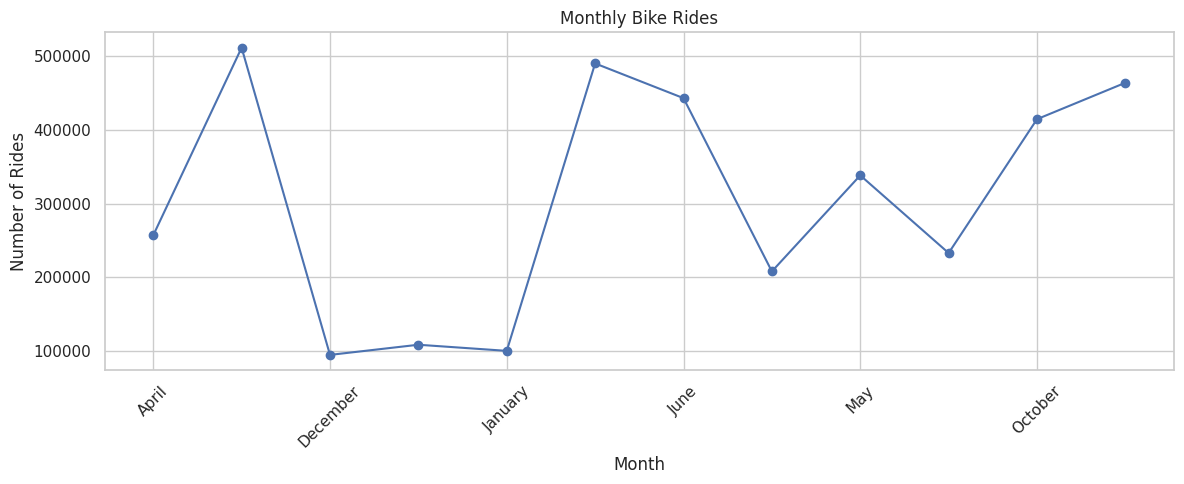

In [ ]:
# Tren bulanan
monthly_rides = (
    df_clean.groupby("month")["ride_id"]
      .nunique()
      .sort_index()
)

monthly_rides.plot(
    kind="line",
    marker="o",
    figsize=(12, 5)
)

plt.title("Monthly Bike Rides")
plt.xlabel("Month")
plt.ylabel("Number of Rides")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

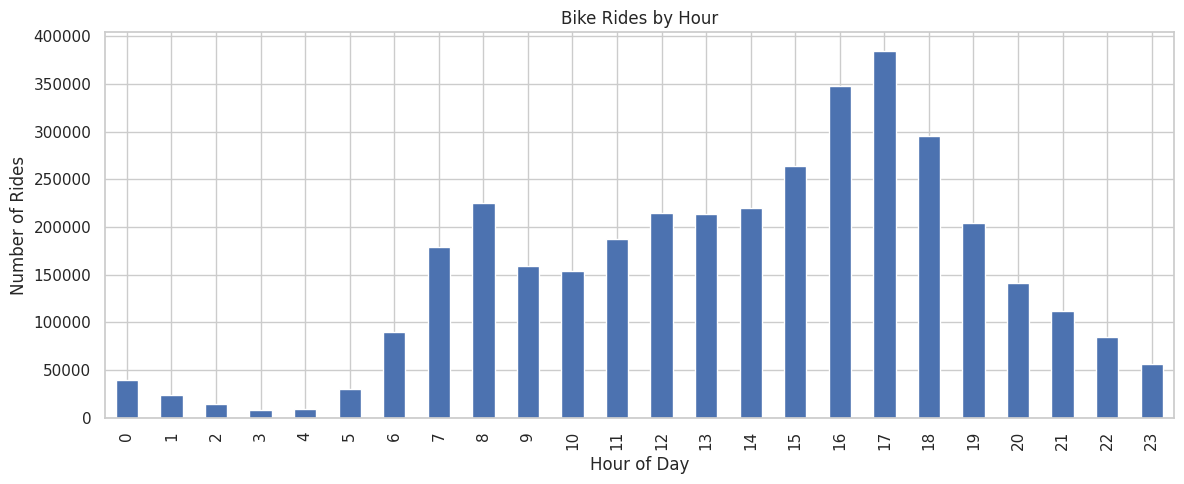

In [ ]:
# Perjalanan berdasarkan jam
hourly_rides = (
    df_clean.groupby("hour_of_day")["ride_id"]
      .nunique()
      .reindex(range(24), fill_value=0)
)

hourly_rides.plot(kind="bar", figsize=(12, 5))

plt.title("Bike Rides by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Rides")
plt.tight_layout()
plt.show()

In [ ]:
# Perjalanan berdasarkan hari
day_type_summary = (
    df_clean.groupby("day_of_week")
      .agg(
          total_rides=("ride_id", "nunique"),
          avg_duration=("ride_length_min", "mean")
      )
      .round(2)
)

display(day_type_summary)

heatmap_data = df_clean.pivot_table(
    index="day_of_week",
    columns="hour_of_day",
    values="ride_id",
    aggfunc="nunique",
    fill_value=0
)

display(heatmap_data)

,total_rides,avg_duration
day_of_week,,
Friday,554215,16.11
Monday,499307,15.09
Saturday,555594,19.42
Sunday,470074,19.61
Thursday,544596,14.33
Tuesday,528079,14.31
Wednesday,509687,13.67


hour_of_day,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_of_week,,,,,,,,,,,,,,,,,,,,,
Friday,5213,2955,1720,1023,1290,4888,13490,25282,31043,22678,...,34213,42961,53372,56059,45303,31860,21725,17524,15429,13195
Monday,3568,1970,1198,850,1228,5205,15517,29880,35256,20708,...,26698,34110,50823,61304,44278,29964,19920,14553,9204,4979
Saturday,10969,7362,4579,2365,1312,1997,5035,9576,17747,26408,...,45369,45590,44805,39701,34854,26340,19171,16932,16341,12654
Sunday,10573,6915,4563,2504,1789,2011,4473,7828,13396,21462,...,39825,39990,38738,34724,31001,22673,16448,12053,9260,5543
Thursday,3363,1681,935,643,1174,5006,16341,34142,41924,23812,...,27437,36271,54203,65186,47553,31657,21435,17073,13196,8369
Tuesday,2940,1392,884,608,1215,5692,17836,36582,43715,22224,...,23774,33504,54709,66389,47903,31882,21557,16934,10283,5395
Wednesday,3146,1792,1009,686,1147,5790,17337,35660,41792,21937,...,23041,31417,51177,61578,44340,30154,21408,17319,11210,6059


In [ ]:
# Perbandingan tipe pelanggan dan jenis sepeda
customer_bike = pd.crosstab(
    df_clean["member_casual"],
    df_clean["rideable_type"]
)

display(customer_bike)

rideable_type,classic_bike,electric_bike
member_casual,,
casual,667942,642174
member,1274437,1076999


In [ ]:
# Persentase jenis sepeda di masing-masing tipe pelanggan
customer_bike_pct = pd.crosstab(
    df_clean["member_casual"],
    df_clean["rideable_type"],
    normalize="index"
).mul(100).round(2)

display(customer_bike_pct)

rideable_type,classic_bike,electric_bike
member_casual,,
casual,50.98,49.02
member,54.20,45.80


In [ ]:
# Rata-rata durasi berdasarkan pelanggan dan jenis sepeda
bike_duration = (
    df_clean.groupby(["member_casual", "rideable_type"])
      ["ride_length_min"]
      .agg(["count", "mean", "median"])
      .round(2)
)

display(bike_duration)

count   mean  median
member_casual rideable_type                        
casual        classic_bike    667942  29.32   16.28
              electric_bike   642174  15.51   10.44
member        classic_bike   1274437  13.66    9.21
              electric_bike  1076999  11.00    8.34

In [ ]:
# Top 10 stasiun asal
top_start = (
    df_clean.groupby("start_station_name")
      .agg(
          total_rides=("ride_id", "nunique"),
          avg_duration=("ride_length_min", "mean")
      )
      .sort_values("total_rides", ascending=False)
      .head(10)
      .round(2)
)

display(top_start)

,total_rides,avg_duration
start_station_name,,
DuSable Lake Shore Dr & Monroe St,35996,30.17
Kingsbury St & Kinzie St,34465,10.11
Navy Pier,31566,29.62
Michigan Ave & Oak St,30834,29.73
DuSable Lake Shore Dr & North Blvd,30009,23.16
Streeter Dr & Grand Ave,27389,30.94
Clinton St & Washington Blvd,26715,11.05
Clinton St & Madison St,25261,12.06
Clark St & Elm St,25223,13.45


In [ ]:
# Top 10 stasiun tujuan
top_end = (
    df_clean.groupby("end_station_name")
      .agg(total_rides=("ride_id", "nunique"))
      .sort_values("total_rides", ascending=False)
      .head(10)
)

display(top_end)

,total_rides
end_station_name,
DuSable Lake Shore Dr & Monroe St,34540
Kingsbury St & Kinzie St,34406
Navy Pier,31664
DuSable Lake Shore Dr & North Blvd,31531
Michigan Ave & Oak St,31012
Streeter Dr & Grand Ave,27758
Clinton St & Washington Blvd,26569
Clinton St & Madison St,25428
Clark St & Elm St,25305


In [ ]:
# Rute paling populer
top_routes = (
    df_clean.dropna(subset=["start_station_name", "end_station_name"])
      .groupby(["start_station_name", "end_station_name"])
      .agg(
          total_rides=("ride_id", "nunique"),
          avg_duration=("ride_length_min", "mean")
      )
      .reset_index()
      .sort_values("total_rides", ascending=False)
      .head(20)
)

display(top_routes)

,start_station_name,end_station_name,total_rides,avg_duration
66611,DuSable Lake Shore Dr & Monroe St,DuSable Lake Shore Dr & Monroe St,6469,33.913110
143212,Navy Pier,Navy Pier,5487,34.762085
70742,Ellis Ave & 60th St,Ellis Ave & 55th St,4424,5.504024
70455,Ellis Ave & 55th St,Ellis Ave & 60th St,4249,4.726703
191506,Streeter Dr & Grand Ave,Streeter Dr & Grand Ave,4204,36.619493
132612,Michigan Ave & Oak St,Michigan Ave & Oak St,4178,43.963672
70819,Ellis Ave & 60th St,University Ave & 57th St,3794,4.537557
194254,University Ave & 57th St,Ellis Ave & 60th St,3752,4.571562
66784,DuSable Lake Shore Dr & Monroe St,Navy Pier,2889,24.592298
68178,Dusable Harbor,Dusable Harbor,2697,33.962299


# Save Clean Data

In [ ]:
output_file_path = os.path.join(output_dir, 'cyclistic_cleaned_data.csv')
df_clean.to_csv(output_file_path, index=False)